# MRAF y la región de señal

**Pregunta:** ¿Cómo cambia la libertad de amplitud en región mixta (MRAF) eficiencia por un potencial moldeado preciso, en un disco y en un anillo, y hasta dónde puede llegar el parámetro de mezcla?

- **Nivel:** 3, Comparación con métodos publicados
- **Requisitos previos:** notebooks 01 y 02 de este tema y notebook 01 del tema 03
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Un arreglo de trampas quiere luz en puntos. Un potencial moldeado, un disco, un anillo o una línea, quiere luz repartida sobre una región con un perfil prescrito, y el experimento se preocupa del perfil: un disco plano atrapa un gas con densidad uniforme, un anillo lleva una corriente persistente. Gerchberg-Saxton simple, ejecutado con la forma como objetivo y cero en todo lo demás, da un perfil pobre, y la libertad de amplitud en región mixta (MRAF) deja que parte de la luz vaya a otra parte para que el perfil pueda ser plano. Su inicio suave es en sí mismo un holograma, preciso y oscuro, y el notebook lo evalúa, para que lo que agregan las iteraciones se mida contra el punto desde donde partieron. Medirás ambos en un disco y en un anillo, recorrerás el parámetro de mezcla para ver de dónde viene la precisión y qué cuesta, y probarás la única elección que el método deja a quien lo usa, el inicio.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import copy
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.core import score
from pipeline.io.contract import read_cases, validate_records
from pipeline.model.holo.core import forward, geometry
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m08_mraf
import slmsuite
from slmsuite.holography.algorithms import Hologram

slmsuite.configure_logging(None)  # sin registro de consola dentro de las salidas

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def shape_numbers(phi, target, setup):
    """Los dos números del producto para una forma: el error (``score.signal_error_pct`` sobre 100) y la
    fracción de la potencia en la región de señal."""
    field = forward.fft_focal_field(phi, setup)
    error = score.signal_error_pct(field, target, setup) / 100.0
    return error, np.sum(np.abs(field[target.mask]) ** 2) / setup.n_pix**2


numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C04: un disco de 15 um de radio sobre el SLM de 256 por 256 píxeles, cuyo dispositivo (8 bits y crosstalk) no se usa aquí; una copia de su registro con un anillo de 20 um de radio y 8 um de ancho da la segunda forma.

In [2]:
# el caso C04 da el SLM, el haz y el disco; una copia de su registro con un anillo como objetivo da la segunda forma
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec_disc = records["C04_disc_crosstalk"]
rec_ring = copy.deepcopy(rec_disc)
rec_ring["target"] = {"kind": "shaped", "shape": "ring", "radius_um": 20.0, "width_um": 8.0, "signal_margin_bins": 3}
setup = setup_of(rec_disc)
shapes = {"disc": target_of(rec_disc), "ring": target_of(rec_ring)}
seed = rec_disc["seed"]
for name, target in shapes.items():
    print(f"{name}: {int((target.amplitude > 0).sum())} bins, región de señal {int(target.mask.sum())} bins")

disc: 2861 bins, región de señal 3389 bins
ring: 4064 bins, región de señal 5432 bins


## Método

Un objetivo moldeado es una amplitud objetivo $T$ dentro de una región de señal SR, dibujada sobre la grilla focal. En Gerchberg-Saxton simple el campo focal se reemplaza por $T$ dentro de SR y por cero fuera, lo que obliga a toda la luz que no cabe en la forma a entrar en la forma. MRAF (Pasienski y DeMarco 2008, ecuación 1, https://doi.org/10.1364/OE.16.002176) mantiene una región de ruido NR fuera de SR y reemplaza el campo por
$$G^{(n)} = \big\{ m\,T\big|_{SR} + (1-m)\,|E^{(n)}|\big|_{NR} \big\} e^{i\arg E^{(n)}},\qquad \phi^{(n+1)} = \arg\mathcal{F}^{-1}G^{(n)},$$
de modo que dentro de SR la amplitud se fuerza a $mT$ y en NR conserva $(1-m)$ de lo que hizo el holograma. La potencia que la forma no necesita drena a NR. Con $m = 1$ el método es Gerchberg-Saxton simple, cuya actualización es la de Di Leonardo et al. (2007, https://doi.org/10.1364/OE.15.001913) con ruido cero. La región de señal del producto es la forma dilatada en 3 bins, de modo que el margen oscuro alrededor de la forma cuenta como señal. Dos números miden un resultado: el error $\eta = \sqrt{\langle((sI - T^2)/T^2)^2\rangle}$ sobre la forma erosionada en una celda de resolución (dos bins), con $s$ el factor que reescala la intensidad al objetivo, que es la ecuación 2 del mismo artículo, y la fracción de la potencia de entrada que cae en SR.


**Las ecuaciones restantes en forma destacada.** De cada holograma de este notebook se leen dos cantidades, el error del perfil y la fracción de la potencia de entrada que cae en la región de señal, y la referencia fijada se maneja con una sola conversión del parámetro de mezcla. Con $E$ el campo focal, $N^2$ el número de píxeles del SLM, $T$ el objetivo, $s$ la escala que ajusta la intensidad al objetivo y SR la región de señal,

$$\eta=\sqrt{\Big\langle\Big(\frac{s\,|E|^2-T^2}{T^2}\Big)^2\Big\rangle_{\text{región de medida}}}, \qquad P_{\text{SR}}=\frac{1}{N^2}\sum_{\mathbf q\in\text{SR}}|E_{\mathbf q}|^2, \qquad f_{\text{slmsuite}}=\frac{1-m}{m},$$

donde $\eta$ es el error de Pasienski y DeMarco 2008 (Ec. 2), $P_{\text{SR}}$ la eficiencia de un objetivo con forma y $f_{\text{slmsuite}}$ el valor de la opción `mraf_factor` de slmsuite que reproduce la mezcla $m$: la biblioteca multiplica la región de ruido por el factor, y el producto conserva $1-m$ de ella frente a $m$ para la señal, de modo que la razón es $(1-m)/m$, que vale 2,33 para el $m=0{,}3$ por defecto del producto. El compromiso del notebook es la curva $\big(P_{\text{SR}}(m),\eta(m)\big)$ que traza $m$: en $m=1$ termina en Gerchberg-Saxton simple, alta eficiencia y error grande, y al bajar $m$ el error baja y la eficiencia baja con él, hasta que la curva da vuelta en los valores más pequeños de $m$, donde la región de señal recibe tan poca luz que la iteración se estanca (el barrido de abajo muestra ese giro).

Primero la comparación misma. La celda ejecuta Gerchberg-Saxton simple y MRAF (mezcla 0,3, el valor por defecto del producto) en el disco y en el anillo durante las 30 iteraciones del caso, y evalúa cada holograma con los dos números de arriba, calculados en el notebook a partir del campo focal. El error que cada método guarda en su propio historial se imprime al lado, como comprobación de que la evaluación es la del método.

In [3]:
# GS (sin región de ruido) y MRAF con mezcla 0.3 en ambas formas, 30 iteraciones, el inicio propio del motor
budget = Budget(rec_disc["budget"]["iterations"])
runs = {}
for shape, target in shapes.items():
    runs[(shape, "Gerchberg-Saxton")] = m04_gs.run(setup, target, budget=budget, rng=Rng(seed))
    runs[(shape, "MRAF")] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=0.3)
for (shape, name), res in runs.items():
    err, eff = shape_numbers(res.phi, shapes[shape], setup)
    print(f"{shape} {name}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
    print(f"     error del historial del método = {res.history[-1]['error']:.4f}")

disc Gerchberg-Saxton: error = 0.4411, fracción de potencia en la señal = 0.9621
     error del historial del método = 0.4411
disc MRAF: error = 0.0517, fracción de potencia en la señal = 0.1719
     error del historial del método = 0.0517
ring Gerchberg-Saxton: error = 0.2340, fracción de potencia en la señal = 0.9632
     error del historial del método = 0.2340
ring MRAF: error = 0.0373, fracción de potencia en la señal = 0.1814
     error del historial del método = 0.0373


### Sensibilidad: la mezcla y la partida

El parámetro de mezcla es la perilla. La celda ejecuta MRAF en el disco para $m$ igual a 0,1, 0,2, 0,3, 0,5 y 0,7 e imprime el error y la potencia en la señal de cada uno; $m = 1$ es la corrida de Gerchberg-Saxton de la celda anterior.

In [4]:
# el compromiso: el parámetro de mezcla de 0.1 (región de ruido casi libre) a 0.7, en el disco
sweep = {}
for mixing in (0.1, 0.2, 0.3, 0.5, 0.7):
    res = m08_mraf.run(setup, shapes["disc"], budget=budget, rng=Rng(seed), mixing=mixing)
    sweep[mixing] = shape_numbers(res.phi, shapes["disc"], setup)
    err, eff = sweep[mixing]
    print(f"m = {mixing:.1f}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
sweep[1.0] = shape_numbers(runs[("disc", "Gerchberg-Saxton")].phi, shapes["disc"], setup)

m = 0.1: error = 0.0371, fracción de potencia en la señal = 0.0123
m = 0.2: error = 0.0272, fracción de potencia en la señal = 0.0621
m = 0.3: error = 0.0517, fracción de potencia en la señal = 0.1719
m = 0.5: error = 0.2882, fracción de potencia en la señal = 0.7407
m = 0.7: error = 0.3852, fracción de potencia en la señal = 0.9485


MRAF no dice dónde partir. El producto parte de una fase de lente de Fresnel de 20 ondas en el borde de la apertura, un holograma suave cuyo campo focal es un punto ancho. La celda ejecuta MRAF con la misma mezcla desde una fase aleatoria uniforme, sorteada con la semilla, e imprime los mismos dos números junto a los del inicio de Fresnel.

In [5]:
# el inicio importa: el inicio suave de Fresnel del motor frente a una fase aleatoria uniforme, misma mezcla 0.3
random_start = m08_mraf.run(setup, shapes["disc"], budget=budget, rng=Rng(seed), mixing=0.3, start_waves=None)
err, eff = shape_numbers(random_start.phi, shapes["disc"], setup)
print(f"inicio aleatorio: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
fresnel_numbers = shape_numbers(runs[("disc", "MRAF")].phi, shapes["disc"], setup)
print(f"inicio de Fresnel: error = {fresnel_numbers[0]:.4f}, "
      f"fracción de potencia en la señal = {fresnel_numbers[1]:.4f}")

inicio aleatorio: error = 0.3004, fracción de potencia en la señal = 0.1771
inicio de Fresnel: error = 0.0517, fracción de potencia en la señal = 0.1719


El inicio de MRAF es en sí mismo un holograma, una lente de Fresnel de 20 ondas en el borde de la apertura (el valor por defecto del método), y tiene un error propio. La celda evalúa ese inicio solo, en ambas formas, con la misma función que todo otro holograma del notebook.

In [6]:
# el inicio solo, evaluado como todo holograma: la lente de Fresnel de 20 ondas desde la que parte MRAF
x, y = geometry.slm_grid(setup)
fresnel_start = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
start_numbers = {shape: shape_numbers(fresnel_start, target, setup) for shape, target in shapes.items()}
for shape, (err, eff) in start_numbers.items():
    print(f"{shape}, el inicio solo: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
    gain = shape_numbers(runs[(shape, "MRAF")].phi, shapes[shape], setup)[1] / eff
    print(f"     ganancia de potencia de las 30 iteraciones de MRAF sobre el inicio: {gain:.2f}")


disc, el inicio solo: error = 0.0322, fracción de potencia en la señal = 0.0887
     ganancia de potencia de las 30 iteraciones de MRAF sobre el inicio: 1.94
ring, el inicio solo: error = 0.0376, fracción de potencia en la señal = 0.1297
     ganancia de potencia de las 30 iteraciones de MRAF sobre el inicio: 1.40


Por último, qué tan rápido baja el error. La celda imprime el error del disco en las iteraciones 1, 5, 15 y 30 para Gerchberg-Saxton y para MRAF, a partir de los historiales, y corre MRAF en el disco durante 100 iteraciones para ver si sigue bajando después del presupuesto del caso.

In [7]:
# el error del disco frente a la iteración para GS y MRAF, desde la historia de cada método, y MRAF hasta 100
for name in ("Gerchberg-Saxton", "MRAF"):
    errors = [h["error"] for h in runs[("disc", name)].history]
    picked = ", ".join(f"{errors[k - 1]:.3f}" for k in (1, 5, 15, 30))
    print(f"{name}: error en la iteración 1, 5, 15, 30 = {picked}")
long_mraf = m08_mraf.run(setup, shapes["disc"], budget=Budget(100), rng=Rng(seed), mixing=0.3)
err, eff = shape_numbers(long_mraf.phi, shapes["disc"], setup)
print(f"MRAF en el disco tras 100 iteraciones: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")


Gerchberg-Saxton: error en la iteración 1, 5, 15, 30 = 1.156, 0.585, 0.466, 0.441
MRAF: error en la iteración 1, 5, 15, 30 = 0.118, 0.120, 0.087, 0.052
MRAF en el disco tras 100 iteraciones: error = 0.0268, fracción de potencia en la señal = 0.1823


La primera figura muestra la potencia focal de los dos hologramas del disco en escala logarítmica, en una ventana de 160 por 160 bins alrededor del eje, con la región de señal dibujada como un contorno cian.

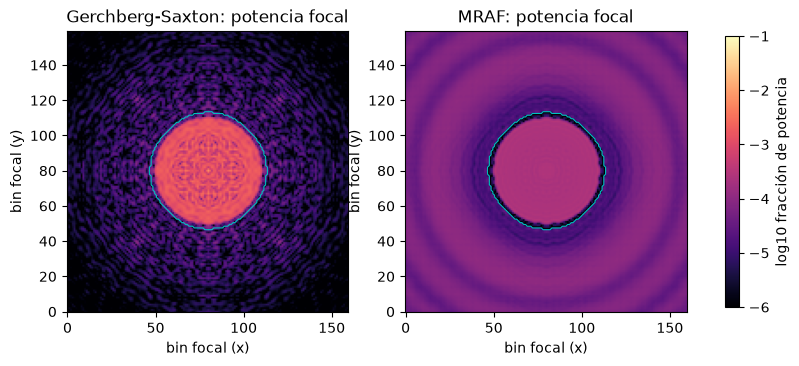

In [8]:
# la potencia focal del disco para GS y para MRAF, una ventana de 160 x 160 bins alrededor del eje, escala logarítmica
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
c = setup.n_fft // 2
for ax, name in zip(axes, ("Gerchberg-Saxton", "MRAF")):
    power = np.abs(forward.fft_focal_field(runs[("disc", name)].phi, setup)) ** 2 * setup.pad**2 / setup.n_pix**2
    window = np.log10(power[c - 80:c + 80, c - 80:c + 80] + 1e-9)
    im = ax.imshow(window, origin="lower", vmin=-6, vmax=-1, cmap="magma")
    ax.contour(shapes["disc"].mask[c - 80:c + 80, c - 80:c + 80], levels=[0.5], colors="c", linewidths=0.8)
    ax.set_title(f"{name}: potencia focal")
    ax.set_xlabel("bin focal (x)")
    ax.set_ylabel("bin focal (y)")
fig.colorbar(im, ax=axes, label="log10 fracción de potencia", shrink=0.8)
plt.show()

Gerchberg-Saxton simple llena el disco con un patrón de ondulaciones que tiene la simetría del SLM, y fuera del contorno hay solo un fondo débil: toda la luz está en la región de señal, y no es plana. MRAF tiene un disco plano con un borde limpio y llena la región fuera del contorno con anillos de luz tenue varias veces más débil que el disco en la escala logarítmica, que es la región de ruido en acción. Esa luz no se desperdicia por accidente: es adonde va la luz que el disco plano no puede usar. La figura no muestra que el perfil sea plano hasta un número dado, lo que sí hace el error, ni lo que harían los anillos en un experimento: un potencial hecho del disco y un halo no es el potencial del disco.

La segunda figura tiene dos paneles. A la izquierda, el error (rojo, eje izquierdo, logarítmico) y la potencia en la señal (azul, eje derecho) contra el parámetro de mezcla para el disco. A la derecha, el error contra la iteración para Gerchberg-Saxton y MRAF.

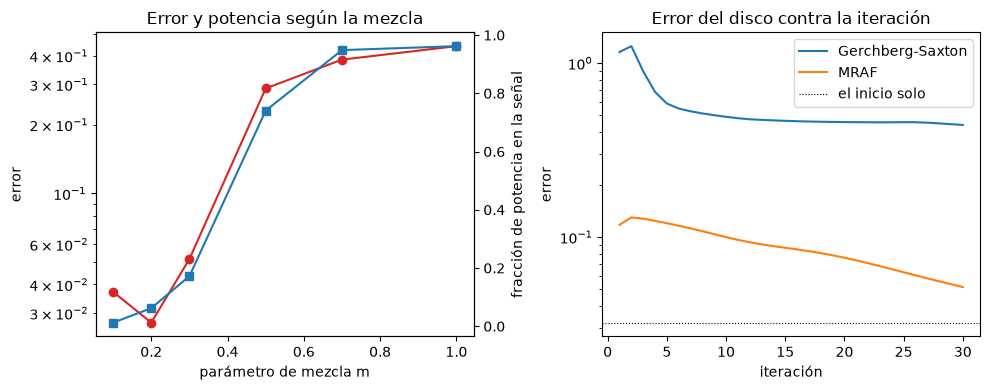

In [9]:
# izquierda: error y eficiencia frente al parámetro de mezcla; derecha: el error del disco frente a la iteración
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
mixes = sorted(sweep)
ax1.semilogy(mixes, [sweep[m][0] for m in mixes], "o-", color="C3", label="error")
ax1.set_xlabel("parámetro de mezcla m")
ax1.set_ylabel("error")
twin = ax1.twinx()
twin.plot(mixes, [sweep[m][1] for m in mixes], "s-", color="C0", label="fracción de potencia en la señal")
twin.set_ylabel("fracción de potencia en la señal")
ax1.set_title("Error y potencia según la mezcla")
for name in ("Gerchberg-Saxton", "MRAF"):
    history = runs[("disc", name)].history
    ax2.semilogy([h["iteration"] for h in history], [h["error"] for h in history], label=name)
ax2.axhline(start_numbers["disc"][0], color="k", ls=":", lw=0.8, label="el inicio solo")
ax2.set_xlabel("iteración")
ax2.set_ylabel("error")
ax2.set_title("Error del disco contra la iteración")
ax2.legend()
fig.tight_layout()
plt.show()

A la izquierda, ambas curvas suben con $m$: de 0,2 a 0,7 la potencia en la señal pasa de 0,0621 a 0,9485 y el error de 0,0272 a 0,3852, de modo que toda ganancia de eficiencia cuesta precisión, y con $m = 1$ el método es Gerchberg-Saxton simple con su error de 0,4411 y su 0,9621 de la potencia en la región de señal. El error no es monótono en el extremo bajo: con $m = 0,1$ es 0,0371 y la región de señal tiene solo 0,0123 de la potencia, de modo que el error más bajo del recorrido está en $m = 0,2$, donde el método ya es 12 veces menos eficiente que con $m = 0,5$. A la derecha el error de Gerchberg-Saxton se estanca cerca de 0,44 tras 15 iteraciones. MRAF queda muy por debajo de él, pero no por debajo de su propio inicio: el inicio de Fresnel solo obtiene 0,0322 (la línea punteada), la primera iteración salta a 0,118, y el error baja luego a 0,052 en la trigésima, aún sobre el inicio; corrido hasta 100 iteraciones el disco llega a 0,0268, bajo el inicio, con 0,1823 de la potencia en la región de señal frente a 0,0887 del inicio. Las 30 iteraciones del caso compran entonces potencia en este disco, cerca del doble que el inicio, y la precisión del inicio se recupera solo más tarde. Pasienski y DeMarco corrieron sus seis objetivos de prueba con mezclas entre 0,30 y 0,40 (el pie de su Fig. 6), los valores que dieron su menor error; en este disco y esta grilla el menor error del recorrido está en 0,2, una diferencia que el notebook no explica (sus objetivos, grillas e inicios no son estos).

## Comparación

slmsuite es una biblioteca de Python de código abierto para calcular hologramas en SLM, y su MRAF es la referencia que ejecutan quienes usan el campo para potenciales moldeados. En su `Hologram` la amplitud objetivo es un arreglo sobre la grilla de Fourier con relleno, un píxel igual a NaN es una región de ruido, y la opción `mraf_factor` multiplica la región de ruido por un número. Con la notación de la sección Método, slmsuite conserva la amplitud de señal y escala la región de ruido, que es la mezcla $m$ de DinHot con el factor $(1-m)/m$; para $m = 0,3$ el factor es 7/3. Todo lo demás queda en el valor por defecto de slmsuite. Las entradas son las del producto: la misma región de señal, el mismo haz gaussiano normalizado, 30 iteraciones y, en la primera corrida, el mismo inicio de Fresnel que MRAF, pasado con el argumento `phase`.

La celda ejecuta el MRAF de slmsuite en el disco y en el anillo e imprime, junto a los números de MRAF de la sección Método, el error y la potencia en la señal de cada uno.

In [10]:
# el MRAF de slmsuite en ambas formas: región de ruido = NaN, factor (1 - m) / m con m = 0.3, el inicio de Fresnel de
# MRAF
beam = geometry.input_amplitude(setup)
factor = (1 - 0.3) / 0.3
slm = {}
for shape, target in shapes.items():
    goal = np.where(target.mask, target.amplitude, np.nan)
    holo = Hologram(goal, slm_shape=(setup.n_pix, setup.n_pix), amp=beam, phase=fresnel_start.copy())
    holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
    slm[shape] = np.array(holo.get_phase(), dtype=float)
    ours = shape_numbers(runs[(shape, "MRAF")].phi, target, setup)
    theirs = shape_numbers(slm[shape], target, setup)
    print(f"{shape} MRAF: error = {ours[0]:.4f}, fracción de potencia en la señal = {ours[1]:.4f}")
    print(f"{shape} slmsuite: error = {theirs[0]:.4f}, fracción de potencia en la señal = {theirs[1]:.4f}")

disc MRAF: error = 0.0517, fracción de potencia en la señal = 0.1719
disc slmsuite: error = 0.0517, fracción de potencia en la señal = 0.1719
ring MRAF: error = 0.0373, fracción de potencia en la señal = 0.1814
ring slmsuite: error = 0.0373, fracción de potencia en la señal = 0.1814


Quien no precondiciona obtiene el inicio propio de slmsuite, una fase aleatoria. La celda ejecuta ese caso en el disco, sembrado, e imprime los mismos dos números.

In [11]:
# slmsuite desde su inicio por defecto, una fase aleatoria, en el disco: lo que obtiene quien lo usa sin preparar el
# inicio
np.random.seed(seed)
goal = np.where(shapes["disc"].mask, shapes["disc"].amplitude, np.nan)
holo = Hologram(goal, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
slm_random = np.array(holo.get_phase(), dtype=float)
err, eff = shape_numbers(slm_random, shapes["disc"], setup)
print(f"slmsuite, inicio aleatorio: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")

slmsuite, inicio aleatorio: error = 0.2866, fracción de potencia en la señal = 0.1774


La figura compara el error de la forma para Gerchberg-Saxton simple, el MRAF del producto y el MRAF de slmsuite, en ambas formas, en un eje logarítmico.

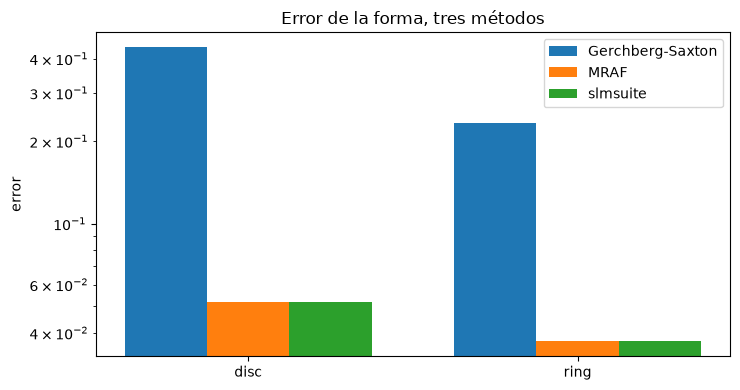

In [12]:
# el error de la forma para GS, el MRAF del producto y el de slmsuite, en ambas formas, eje logarítmico
fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.25
rows = (("Gerchberg-Saxton", {k: runs[(k, "Gerchberg-Saxton")].phi for k in shapes}), ("MRAF", {k: runs[(k,
    "MRAF")].phi for k in shapes}),
        ("slmsuite", slm))
for k, (label, phis) in enumerate(rows):
    errors = [shape_numbers(phis[shape], shapes[shape], setup)[0] for shape in shapes]
    ax.bar(np.arange(2) + (k - 1) * width, errors, width, label=label)
ax.set_yscale("log")
ax.set_xticks(range(2), list(shapes))
ax.set_ylabel("error")
ax.set_title("Error de la forma, tres métodos")
ax.legend()
fig.tight_layout()
plt.show()

Las barras de MRAF y del MRAF de slmsuite tienen la misma altura en ambas formas, y ambas quedan muy por debajo de Gerchberg-Saxton simple, cuyas barras son 0,4411 en el disco y 0,2340 en el anillo. La coincidencia es el punto: el MRAF del producto calcula lo que calcula el MRAF de la biblioteca, cuando ambos parten de la misma fase, y la diferencia de 0,2866 frente a 0,0517 en el disco entre el inicio aleatorio de slmsuite y el inicio de Fresnel dice que el inicio es lo que debe elegir quien usa el método. La figura compara una mezcla y 30 iteraciones, y no dice cómo se comporta cada implementación con los otros valores de la mezcla recorridos arriba.

### Úsalo con tus propios datos

La forma del potencial propio de un desarrollador no necesita una función nueva: el producto la lee como un bloque `target` del registro de parámetros del contrato 1, con el tipo `shaped` y una de las formas que conoce (`disc`, `top_hat`, `ring`, `lg_ring`, `line`) con sus tamaños en micrómetros y los `signal_margin_bins` del margen oscuro. La celda siguiente escribe el registro de una línea de 40 um por 6 um, copiando el montaje, el haz y el presupuesto de C04, y hace que el contrato lo acepte antes de calcular nada; `target_of` dibuja entonces la forma en la grilla focal centrada y la dilata por el margen para hacer la región de señal. El barrido de la mezcla que este notebook hizo con el disco se repite con la línea en cuatro valores, con la misma llamada `m08_mraf.run(setup, target, budget=..., rng=..., mixing=...)`, y cada holograma se puntúa con los dos números del notebook, el error y la fracción de potencia de señal. La regla que sale del compromiso es tomar la mayor mezcla que mantiene el error bajo la tolerancia del experimento, porque una mezcla mayor guarda más luz en la región de señal.

In [13]:
# una forma propia escrita como registro de parámetros: una línea de 40 um por 6 um, aceptada por el contrato 1
my_rec = copy.deepcopy(rec_disc)
my_rec["case_id"] = "C91_my_line"
my_rec["target"] = {"kind": "shaped", "shape": "line", "length_um": 40.0, "width_um": 6.0, "signal_margin_bins": 3}
print("contrato 1:", validate_records([my_rec]).summary())
my_target = target_of(my_rec)
print(f"bins en la forma {int((my_target.amplitude > 0).sum())}, región de señal {int(my_target.mask.sum())}")
my_sweep = {}
for mixing in (0.15, 0.2, 0.3, 0.5):
    res = m08_mraf.run(setup, my_target, budget=budget, rng=Rng(seed), mixing=mixing)
    my_sweep[mixing] = shape_numbers(res.phi, my_target, setup)
    print(f"m = {mixing:.2f}: error {my_sweep[mixing][0]:.4f}, fracción de potencia de señal {my_sweep[mixing][1]:.4f}")

contrato 1: 1 accepted, 0 rejected, 0 flagged
bins en la forma 1053, región de señal 1629
m = 0.15: error 0.0362, fracción de potencia de señal 0.0306
m = 0.20: error 0.0379, fracción de potencia de señal 0.0613
m = 0.30: error 0.0469, fracción de potencia de señal 0.1677
m = 0.50: error 0.1807, fracción de potencia de señal 0.7408


El contrato acepta el registro, y la línea tiene 1053 bins en la forma y 1629 en la región de señal. Los errores son 0,0362 con m = 0,15, 0,0379 con 0,20, 0,0469 con 0,30 y 0,1807 con 0,50, con fracciones de potencia de señal de 0,0306, 0,0613, 0,1677 y 0,7408: el mismo compromiso que en el disco, en el mismo sentido y con el mismo codo, el error quedándose cerca de 0,04 mientras la eficiencia crece cinco veces de 0,15 a 0,30 y luego saltando cuatro veces cuando la mezcla pasa de 0,30 a 0,50. Frente a una tolerancia de 5 por ciento, la regla elige m = 0,3, con un error de 0,0469 y una fracción de potencia de señal de 0,1677. La figura dibuja los cuatro puntos en ejes logarítmicos, error contra eficiencia, con la tolerancia como línea punteada.

mezcla elegida: 0.3
error 0.0469, fracción de potencia de señal 0.1677


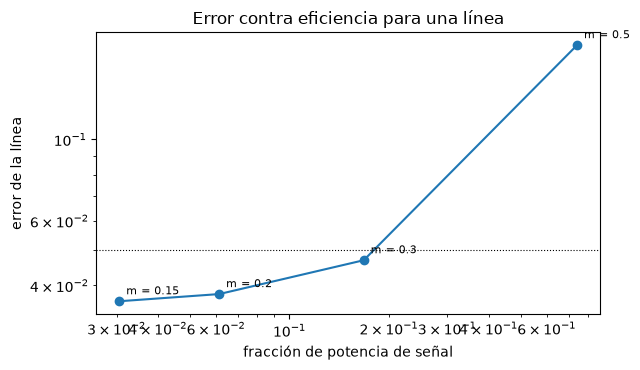

In [14]:
# la regla del notebook aplicada: la mayor mezcla que mantiene el error bajo 5 por ciento, y lo que cuesta
ok = [m for m, (err, eff) in my_sweep.items() if err <= 0.05]
pick = max(ok) if ok else None
print("mezcla elegida:", pick)
if pick is not None:
    print(f"error {my_sweep[pick][0]:.4f}, fracción de potencia de señal {my_sweep[pick][1]:.4f}")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.loglog([v[1] for v in my_sweep.values()], [v[0] for v in my_sweep.values()], "o-")
for mixing, (err, eff) in my_sweep.items():
    ax.annotate(f"m = {mixing}", (eff, err), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.axhline(0.05, color="k", ls=":", lw=0.8)
ax.set_xlabel("fracción de potencia de señal")
ax.set_ylabel("error de la línea")
ax.set_title("Error contra eficiencia para una línea")
fig.tight_layout()
plt.show()

La curva sube desde abajo a la izquierda hacia arriba a la derecha, y los tres primeros puntos quedan bajo la línea punteada mientras el cuarto salta sobre ella: la mezcla compra eficiencia barato hasta cerca de 0,3 y caro más allá, y la línea de 6 um de ancho, de solo unas pocas celdas de resolución, tiene su codo aproximadamente en el mismo lugar que el disco. Cuatro cosas que revisar en una forma propia. Que el contrato acepte el registro, pues una forma más ancha que la ventana o un margen que la máscara no puede contener se rechaza con una razón. Que el error se lea junto con la fracción de potencia de señal, porque la mezcla más pequeña tiene el menor error y casi nada de luz en la región de señal. Que la elección se repita con una partida que no sea la fase de Fresnel suave del motor, que el barrido de arriba mostró que cambia el error en un factor de seis en el disco. Y que la elección se compruebe con la opción $(1-m)/m$ de slmsuite cuando el holograma se vaya a calcular fuera del producto: los dos códigos coinciden solo cuando coinciden la mezcla, la partida y la región de señal. El límite de esta sección es el del notebook: un objetivo, una semilla, el dispositivo ideal y el presupuesto de 30 iteraciones del producto.

## Resultados

**Respuesta:** Frente a Gerchberg-Saxton simple MRAF compra precisión con eficiencia, y el parámetro de mezcla fija el precio, en el producto y en slmsuite por igual. Con la mezcla de 0,3 del producto el error del perfil es 0,0517 en el disco frente a 0,4411 de Gerchberg-Saxton, un factor de 8,5, y 0,0373 en el anillo frente a 0,2340, un factor de 6,3, mientras la fracción de la potencia de entrada en la región de señal baja de 0,9621 a 0,1719 en el disco y de 0,9632 a 0,1814 en el anillo. Frente a su propio inicio la cuenta es otra: el inicio de Fresnel solo ya obtiene 0,0322 en el disco y 0,0376 en el anillo, con apenas 0,0887 y 0,1297 de la potencia en la región de señal, así que en este caso las 30 iteraciones suben la potencia en un factor de 1,94 en el disco (0,1719 frente a 0,0887) y 1,40 en el anillo (0,1814 frente a 0,1297) con un error mayor en el disco e igual en el anillo, y el disco necesita unas 100 iteraciones (0,0268 con 0,1823) para quedar bajo su inicio. A lo largo del recorrido en el disco el error es 0,0272 con $m = 0,2$ y 0,0621 de la potencia en la región de señal, y 0,2882 con $m = 0,5$ y 0,7407; no sigue bajando bajo $m = 0,2$, pues con $m = 0,1$ es 0,0371. El inicio importa tanto como la mezcla: desde una fase aleatoria el mismo método obtiene un error de 0,3004 en vez de 0,0517. Ejecutado con slmsuite 0.5.0 desde el mismo inicio y con el factor 7/3, MRAF da los mismos números a cuatro dígitos (0,0517 y 0,1719 en el disco, 0,0373 y 0,1814 en el anillo), y desde el inicio aleatorio propio de slmsuite el error del disco es 0,2866. Un potencial moldeado preciso de este método es entonces un potencial que desperdicia la mayor parte de su luz, y el experimento tiene que tener la potencia de sobra.

## Resumen

Gerchberg-Saxton no puede hacer un disco plano porque no tiene dónde poner la luz que el disco no quiere; MRAF le da una región de ruido, y un disco plano se vuelve posible al precio de 0,83 de la potencia en el disco. En este disco el inicio suave ya es plano y aún más oscuro, así que las iteraciones de MRAF son las que suben la potencia, y necesitan más que las 30 del caso para dejar el error bajo el del inicio. El parámetro de mezcla se mueve a lo largo de ese intercambio, con una mejor precisión cerca de $m = 0,2$ en esta grilla y un colapso de la ventaja sobre $m = 0,5$, y el inicio suave es parte del método. El notebook siguiente pregunta si un mejor inicio, una fase de transporte óptimo (Swan et al. 2024; Torchylo et al. 2025), cambia el precio.

## Referencias

- Pasienski y DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json y https://pypi.org/project/slmsuite/.
- Swan, Torchylo, Van de Graaff, Rudolph y Hogan, "High-fidelity holographic beam shaping with optimal transport and phase diversity", arXiv 2408.17025 (2024), https://arxiv.org/abs/2408.17025.
- Torchylo, Swan, Tellez y Hogan, arXiv 2512.19072 (2025), la forma separable de Sinkhorn del inicio por transporte óptimo con memoria lineal, https://arxiv.org/abs/2512.19072.